In [ ]:
import numpy as np
import scipy as sp
import scipy.spatial
from collections import deque


class SandPile:
    """SandPile class"""

    def __init__(self, width, height, manna=False, seed=None):
        """Initialize a sandpile with the specified width and height."""
        self.width = width
        self.height = height
        self.manna = manna
        self.rng = np.random.default_rng(seed)
        
        if manna:
            self.threshold = 2
        else:
            self.threshold = 4

        self.grid = np.zeros((width, height), dtype=int)

        # We may want to keep track of the overall mass of the sand pile
        # overtime.  The following array will store the masses at each time
        # step (so that `len(self.mass_history)` is equal to the number of time
        # steps the sand pile has been running).
        self.mass_history = []
        # You probably will want to define other attributes to store statistics.

        # It is good practice to define *all* class attributes in the
        # `__init__` function, even if they get redefined later.  You may want
        # to define variables which are used to keep track of avalanches.
        self.grid_history = []
        

    def drop_sand(self, n=1, site=None):
        """Add `n` grains of sand to the grid.  Each grains of sand is added to
        a random site.

        This function also increments the time by 1 and update the internal
        `mass_history`.  Depending on how you want to code things, you may wish
        to also run the avalanche (alternatively, the avalanching might be
        executed elsewhere).

        Parameters
        ==========

        n: int

          The number of grains of sand of drop at this time step.  If left
          unspecified, defaults to 1.

        site:

          The site on which the grain(s) of sand should be dropped.  If `None`,
          a random site is used.

        """

        if site is None:
            coord = self.rng.integers(low = 0, high = [self.width, self.height])
            site = (int(coord[0]), int(coord[1]))
        
        x, y = site

        self.grid[x][y] += n

        self.mass_history.append(self.mass())

        return site


    def mass(self):
        """Return the mass of the grid."""
        return np.sum(self.grid)

    def topple(self, site):
        """Topple the specified site."""
        x, y = site
        self.grid[x][y] -= 4
        loss = 4

        neighbours = ((x+1, y), (x-1, y), (x, y+1), (x, y-1))

        for neighbour in neighbours:
            nx, ny = neighbour
            if (0 <= nx < self.width) and (0 <= ny < self.height):
                self.grid[nx, ny] += 1
                loss -= 1

        return loss
    
    def topple_manna(self, site):
        """Topple the specified site according to the Manna model."""
        x, y = site
        self.grid[x][y] -= 2
        loss = 2

        neighbours = ((x+1, y), (x-1, y), (x, y+1), (x, y-1))

        to_topple = self.rng.choice(len(neighbours), 2, replace=True)

        for i in to_topple:
            nx, ny = neighbours[i]
            if (0 <= nx < self.width) and (0 <= ny < self.height):
                self.grid[nx][ny] += 1
                loss -= 1

        return loss
        

    def avalanche(self, start, record_history=False):
        """Stabilise the pile and return topples, area, loss and length."""

        topples = 0
        toppled_sites = set()
        loss = 0

        if self.manna:
            topple_func = self.topple_manna
        else:
            topple_func = self.topple

        if record_history:
            self.grid_history = [self.grid.copy()]

        unstable = deque()
        queued = set()

        # check if starting grid is unstable
        if self.grid[start] >= self.threshold:
            unstable.append(start)
            queued.add(start)

        while unstable:
            site = unstable.popleft()
            queued.discard(site)

            if self.grid[site] < self.threshold:
                continue

            loss += topple_func(site)
            topples += 1
            toppled_sites.add(site)

            if record_history:
                self.grid_history.append(self.grid.copy())

            x, y = site

            # only these sites can possibly be unstable
            affected_sites = ((x, y), (x+1, y), (x-1, y), (x, y+1), (x, y-1))

            for nx, ny in affected_sites:
                if (0 <= nx < self.width and 0 <= ny < self.height
                    and self.grid[nx, ny] >= self.threshold
                    and (nx, ny) not in queued):
                    unstable.append((nx, ny))
                    queued.add((nx, ny))

        area = len(toppled_sites)

        x0, y0 = start

        # L1 length
        length = max((abs(x - x0) + abs(y - y0) for x, y in toppled_sites), default=0)

        return topples, area, loss, length



In [ ]:
from collections import deque

def avalanche(self, start, record_history=False, manna=False):
    """Stabilise the pile and return topples, area, loss and length."""

    topples = 0
    toppled_sites = set()
    loss = 0

    if manna:
        topple_func = self.topple_manna
    else:
        topple_func = self.topple

    if record_history:
        self.grid_history = [self.grid.copy()]

    unstable = deque()
    queued = set()

    # Before adding the grain, the grid should already be stable.
    # Therefore, only the starting site can initially be unstable.
    if self.grid[start] >= self.threshold:
        unstable.append(start)
        queued.add(start)

    while unstable:
        site = unstable.popleft()
        queued.discard(site)

        # Defensive check: the site might no longer be unstable
        if self.grid[site] < self.threshold:
            continue

        loss += topple_func(site)
        topples += 1
        toppled_sites.add(site)

        if record_history:
            self.grid_history.append(self.grid.copy())

        x, y = site

        # Only these sites could now be unstable
        affected_sites = (
            (x, y),
            (x + 1, y),
            (x - 1, y),
            (x, y + 1),
            (x, y - 1)
        )

        for nx, ny in affected_sites:
            if (
                0 <= nx < self.width
                and 0 <= ny < self.height
                and self.grid[nx, ny] >= self.threshold
                and (nx, ny) not in queued
            ):
                unstable.append((nx, ny))
                queued.add((nx, ny))

    area = len(toppled_sites)

    x0, y0 = start
    # L1 length
    length = max((abs(x - x0) + abs(y - y0) for x, y in toppled_sites), default=0)


    # Radius of gyration of the avalanche cluster

    #if area > 0:
    #    coordinates = np.array(list(toppled_sites), dtype=float)

    #    centre = np.mean(coordinates, axis=0)
    #    squared_distances = np.sum((coordinates - centre) ** 2, axis=1)

    #    radius = np.sqrt(np.mean(squared_distances))

    #else:
    #    radius = 0.0

    return topples, area, loss, length



    def avalanche(self, start, record_history = False, random_topple = False):
        """Run the avalanche causing all sites to topple and store the stats of
        the avalanche in the appropriate variables.
        """
        
        topples = 0
        toppled_sites = set()
        loss = 0
        length = 0

        if random_topple:
            topple_func = self.topple_random
        else:
            topple_func = self.topple


        # record starting point of an avalance
        if record_history:
            self.grid_history = [self.grid.copy()]

        while True:
            to_topple = []

            # checks first
            for x in range(self.width):
                for y in range(self.height):
                    if self.grid[x, y] >= self.threshold:
                        to_topple.append((x, y))

            # if nothing to topple
            if len(to_topple) == 0:
                break

            # else cause avalanche
            for site in to_topple:
                loss += topple_func(site)
                topples += 1
                toppled_sites.add(site)

                if record_history:
                    self.grid_history.append(self.grid.copy()) # records grids over time in a avalanche

        area = len(toppled_sites)

        lengths = []
        if area != 0:
            x0, y0 = start
            for x, y in toppled_sites:
                # L1 length
                lengths.append(abs(x-x0)+abs(y-y0)) 
        
        if len(lengths) != 0:
            length = max(lengths)

        return topples, area, loss, length

    # You are free (and encouraged) to define more methods within this class

In [504]:
def simulate_avalanche(T, width=3, height=3, start_sites=None, manna=False, seed=None):
    pile = SandPile(width, height, manna=manna, seed=seed)
    results = np.zeros((T, 4))

    if start_sites is not None and len(start_sites) > T:
        raise ValueError("The number of start sites cannot exceed T.")

    for t in range(T):
        if start_sites is not None and t < len(start_sites):
            start = pile.drop_sand(site=start_sites[t])
        else:
            start = pile.drop_sand()

        results[t] = pile.avalanche(start=start)

    return results

In [505]:
pile = SandPile(3, 3)
print(pile.grid)
print(pile.mass())

pile.grid[0, 0] = pile.grid[2, 1] = pile.grid[2, 2] = 1
pile.grid[1, 0] = pile.grid[1, 2] = pile.grid[2, 0] = 2
pile.grid[0, 1] = pile.grid[0, 2] = 3
pile.grid[1, 1] = 4
print(pile.grid)
print(pile.mass())

pile.avalanche((1,1), record_history = True)
print(pile.grid_history)
print(pile.grid)
print(pile.mass_history)

[[0 0 0]
 [0 0 0]
 [0 0 0]]
0
[[1 3 3]
 [2 4 2]
 [2 1 1]]
19
[array([[1, 3, 3],
       [2, 4, 2],
       [2, 1, 1]]), array([[1, 4, 3],
       [3, 0, 3],
       [2, 2, 1]]), array([[2, 0, 4],
       [3, 1, 3],
       [2, 2, 1]]), array([[2, 1, 0],
       [3, 1, 4],
       [2, 2, 1]]), array([[2, 1, 1],
       [3, 2, 0],
       [2, 2, 2]])]
[[2 1 1]
 [3 2 0]
 [2 2 2]]
[]


In [244]:
results = simulate_avalanche(T=100000)
burn_in = 5000

topples = results[burn_in:, 0]
area = results[burn_in:, 1]
loss = results[burn_in:, 2]
length = results[burn_in:, 3]

In [11]:
import matplotlib.pyplot as plt

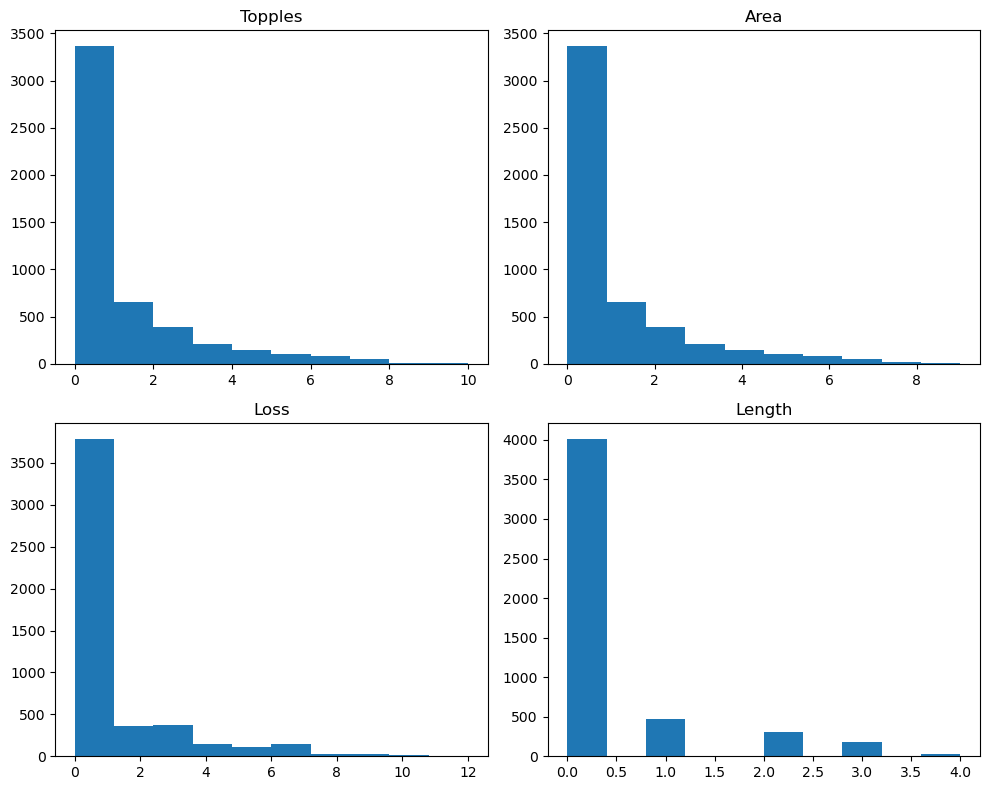

In [98]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))
    
axes[0, 0].hist(topples, bins=10)
axes[0, 0].set_title("Topples")

axes[0, 1].hist(area, bins=10)
axes[0, 1].set_title("Area")

axes[1, 0].hist(loss, bins=10)
axes[1, 0].set_title("Loss")

axes[1, 1].hist(length, bins=10)
axes[1, 1].set_title("Length")

plt.tight_layout()
plt.show()

Topples: prob = -2.38*log x +  0.19 
Area: prob = -1.84*log x + -0.30 
Loss: prob = -2.03*log x + -0.08 
Length: prob = -1.72*log x + -0.41 


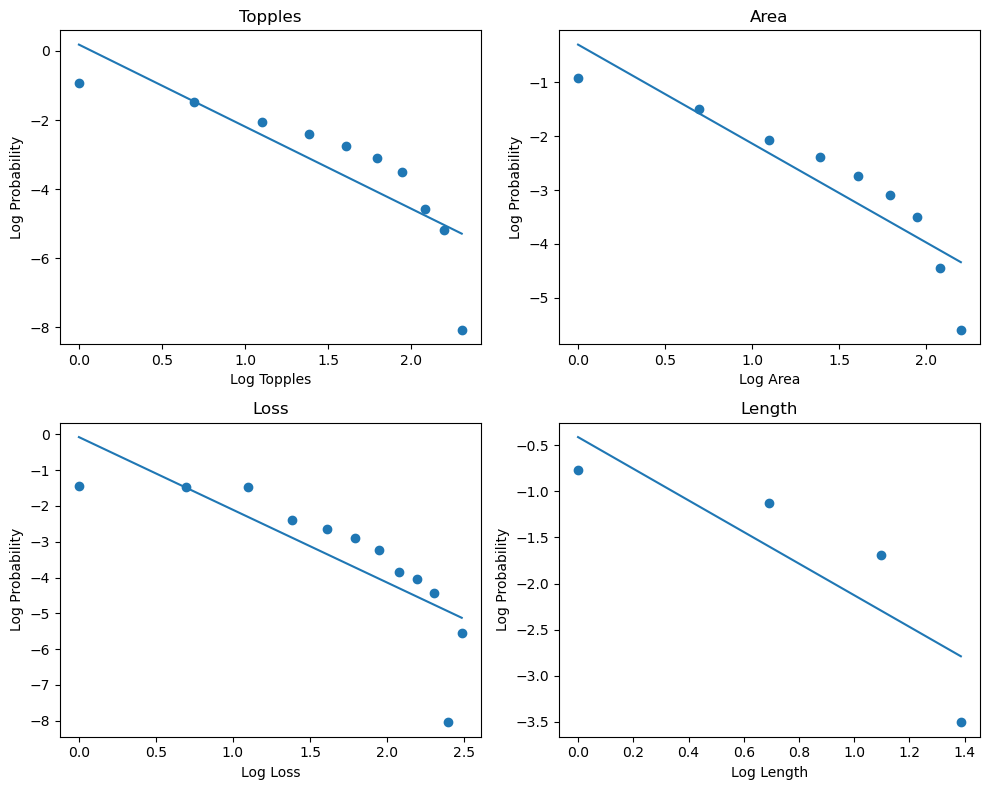

In [99]:
properties = ["Topples", "Area", "Loss", "Length"]

fig, axes = plt.subplots(2,2, figsize=(10, 8))

for col, ax in enumerate(axes.flat):
    curr = results[:, col]
    # strip 0 values since we can't take log 0?
    positive = curr[curr > 0]

    x, counts = np.unique(positive, return_counts=True)
    prob = counts / counts.sum()

    # loglog fit
    alpha, logA = np.polyfit(np.log(x), np.log(prob), 1)
    print(f"{properties[col]}: prob = {alpha: .2f}*log x + {logA: .2f} ")

    ax.plot(np.log(x), alpha*np.log(x)+logA)
    ax.scatter(np.log(x), np.log(prob))

    ax.set_xlabel("Log " + properties[col])
    ax.set_ylabel("Log Probability")
    ax.set_title(properties[col])
plt.tight_layout()
plt.show()



In [ ]:
shape, loc, scale = sp.stats.lognorm.fit(data, floc=0)

In [158]:
def plot_properties(results, plot=True):
    properties = ["Topples", "Area", "Loss", "Length"]

    if plot:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    for col in range(4):
        curr = results[:, col]

        if col == 2:  # Loss
            # Keep zero so it appears in the empirical distribution
            x, counts = np.unique(curr, return_counts=True)
            prob = counts / counts.sum()

            x_fit = x[x > 0]
            log_prob_fit = np.log(prob[x > 0])

            alpha, logA = np.polyfit(x_fit, log_prob_fit, 1)

            print(
                f"Loss: log prob = "
                f"{alpha:.2f} * x + {logA:.2f}"
            )

            if plot:
                ax = axes.flat[col]

                # Show all points, including loss = 0
                ax.scatter(x, np.log(prob))

                # Fit positive loss only
                ax.plot(
                    x_fit,
                    alpha * x_fit + logA,
                )

                ax.set_xlabel("Loss")
                ax.set_ylabel("Log probability")
                ax.set_title("Loss")
                #ax.legend()

        else:  # Topples, Area and Length
            # Remove zero because log(0) is undefined
            positive = curr[curr > 0]

            x, counts = np.unique(positive, return_counts=True)
            prob = counts / counts.sum()

            log_x = np.log(x)
            log_prob = np.log(prob)

            alpha, logA = np.polyfit(log_x, log_prob, 1)

            print(
                f"{properties[col]}: log prob = "
                f"{alpha:.2f} * log x + {logA:.2f}"
            )

            if plot:
                ax = axes.flat[col]

                ax.scatter(log_x, log_prob)
                ax.plot(
                    log_x,
                    alpha * log_x + logA
                )

                ax.set_xlabel("Log " + properties[col])
                ax.set_ylabel("Log probability")
                ax.set_title(properties[col])
                #ax.legend()

    if plot:
        plt.tight_layout()
        plt.show()

#### Base model

In [100]:
T = [5000, 8000, 10000, 20000]

for t in T:
    new_result = simulate_avalanche(T=t)
    plot_properties(results, plot=False)
    print("")

Topples: log prob = -2.38*log x +  0.19 
Area: log prob = -1.84*log x + -0.30 
Loss: log prob = -2.03*log x + -0.08 
Length: log prob = -1.72*log x + -0.41 

Topples: log prob = -2.38*log x +  0.19 
Area: log prob = -1.84*log x + -0.30 
Loss: log prob = -2.03*log x + -0.08 
Length: log prob = -1.72*log x + -0.41 

Topples: log prob = -2.38*log x +  0.19 
Area: log prob = -1.84*log x + -0.30 
Loss: log prob = -2.03*log x + -0.08 
Length: log prob = -1.72*log x + -0.41 

Topples: log prob = -2.38*log x +  0.19 
Area: log prob = -1.84*log x + -0.30 
Loss: log prob = -2.03*log x + -0.08 
Length: log prob = -1.72*log x + -0.41 



Topples: log prob = -1.74*log x +  1.01 
Area: log prob = -1.54*log x +  0.18 
Loss: log prob = -2.70*log x +  1.34 
Length: log prob = -2.00*log x +  0.49 


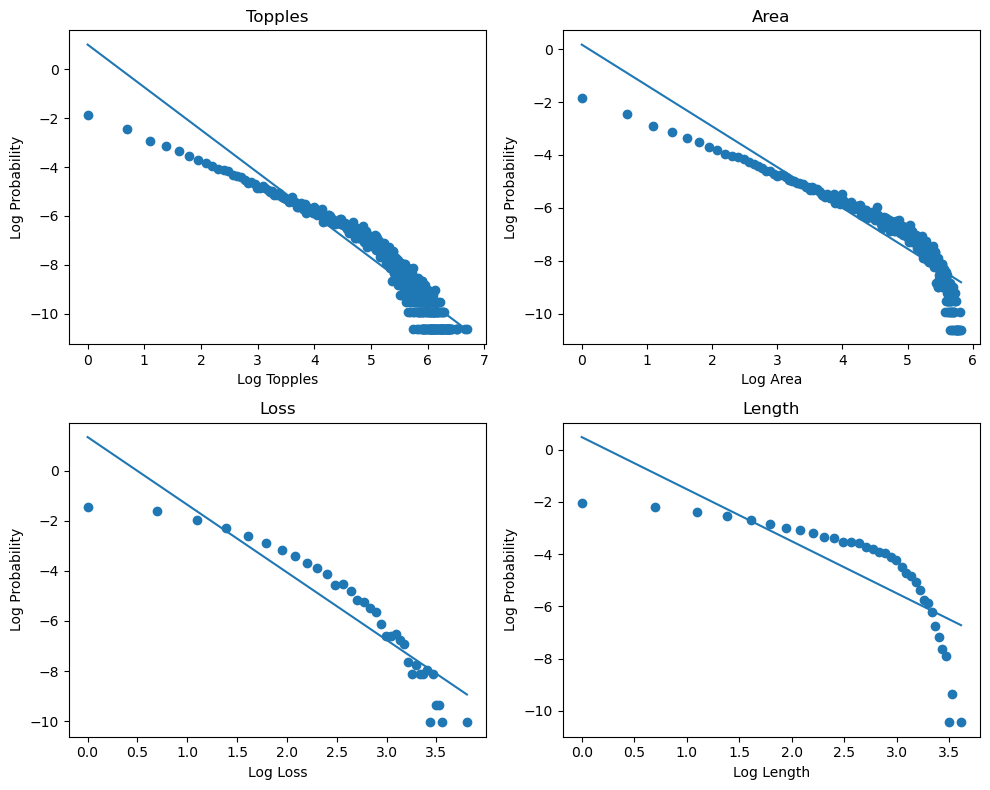

In [101]:
results_1 = simulate_avalanche(T=100000, width=20, height=20)

plot_properties(results_1)



Topples: log prob = -1.74 * log x + 0.99
Area: log prob = -1.53 * log x + 0.14
Loss: log prob = -0.23 * x + -3.06
Length: log prob = -2.00 * log x + 0.50


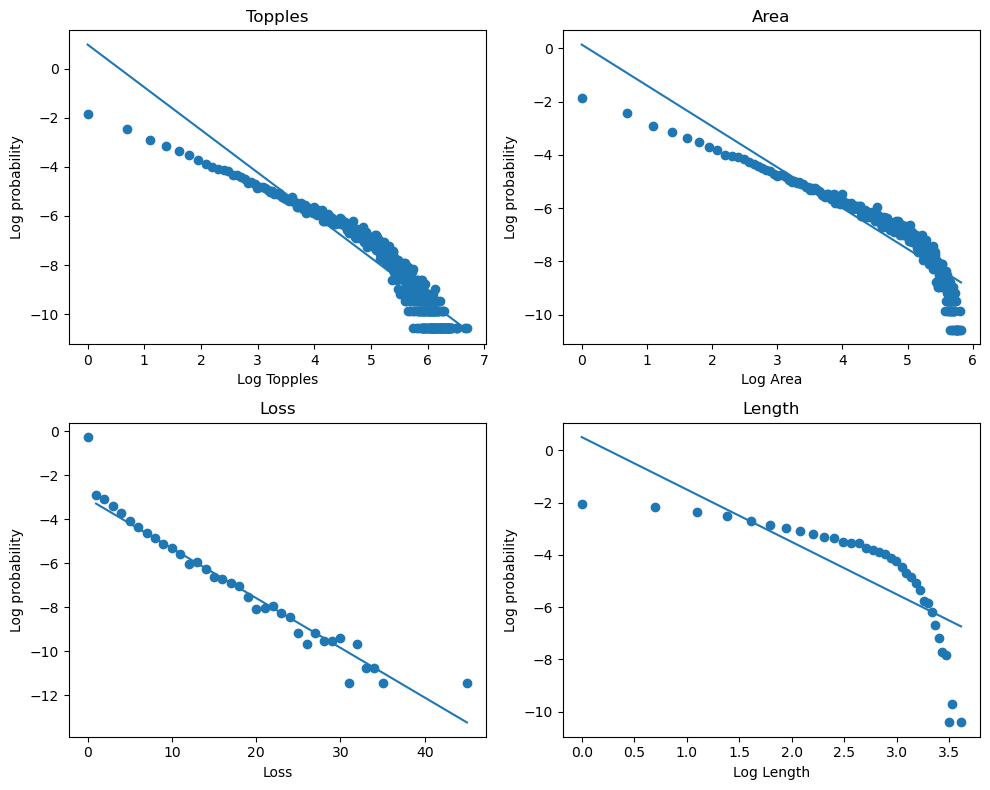

In [222]:
plot_properties(results_1[5000:])

In [224]:
def fit_powerlaw(data, x_max, title=None, plot=True):
    data = data[data > 0]

    x, counts = np.unique(data, return_counts=True)
    prob = counts / counts.sum()

    fit_mask = x <= x_max

    log_x_fit = np.log(x[fit_mask])
    log_prob_fit = np.log(prob[fit_mask])

    alpha, logA = np.polyfit(
        log_x_fit,
        log_prob_fit,
        1
    )

    log_prob_pred = alpha * log_x_fit + logA

    # R² on the same scale used for fitting
    r2 = r2_score(log_prob_fit, log_prob_pred)

    print(
        f"{title}: log prob = "
        f"{alpha:.2f} * log x + {logA:.2f}, "
        f"R² = {r2:.4f}"
    )

    if plot:
        # Show the complete empirical distribution
        plt.scatter(
            np.log(x),
            np.log(prob),
            label="Simulation"
        )

        # Show the fitted line only within the fitting range
        plt.plot(
            log_x_fit,
            log_prob_pred,
            color="red",
            label=f"Fit up to {x_max}"
        )

        plt.axvline(
            np.log(x_max),
            color="grey",
            linestyle=":",
            label="Cutoff"
        )

        plt.xlabel("Log " + (title or "x"))
        plt.ylabel("Log probability")
        plt.title(title)
        plt.legend()
        plt.show()

    return alpha, logA, r2


In [231]:
candidate_cutoff = [100, 150, 200, 250, 300, 350, 400]

for cand in candidate_cutoff:
    _, _, r2 = fit_powerlaw(results_1[5000:, 1], cand, "Area", False)

Area: log prob = -1.03 * log x + -1.68, R² = 0.9895
Area: log prob = -1.05 * log x + -1.63, R² = 0.9870
Area: log prob = -1.12 * log x + -1.38, R² = 0.9696
Area: log prob = -1.25 * log x + -0.93, R² = 0.9294
Area: log prob = -1.44 * log x + -0.21, R² = 0.8591
Area: log prob = -1.53 * log x + 0.14, R² = 0.8337
Area: log prob = -1.53 * log x + 0.14, R² = 0.8337


In [233]:
candidate_cutoff = [150, 160, 170, 175, 180, 190, 200]

for cand in candidate_cutoff:
    _, _, r2 = fit_powerlaw(results_1[5000:, 1], cand, "Area", False)

Area: log prob = -1.05 * log x + -1.63, R² = 0.9870
Area: log prob = -1.06 * log x + -1.59, R² = 0.9847
Area: log prob = -1.06 * log x + -1.57, R² = 0.9845
Area: log prob = -1.08 * log x + -1.52, R² = 0.9803
Area: log prob = -1.09 * log x + -1.50, R² = 0.9790
Area: log prob = -1.10 * log x + -1.44, R² = 0.9746
Area: log prob = -1.12 * log x + -1.38, R² = 0.9696


Area: log prob = -1.08 * log x + -1.53, R² = 0.9809


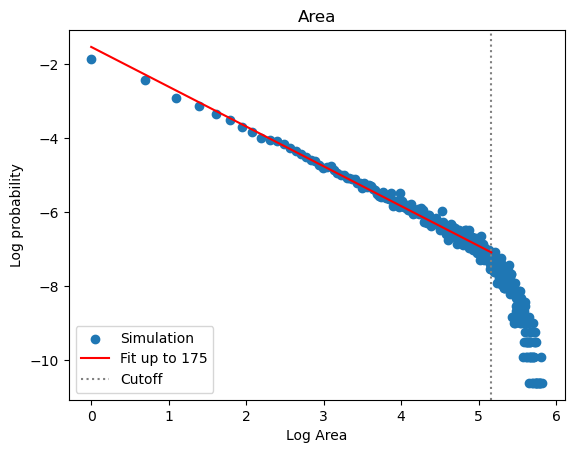

(np.float64(-1.0765632430021894),
 np.float64(-1.5280293187456497),
 0.9808734835631111)

In [234]:
fit_powerlaw(results_1[:, 1], 175, "Area", True)

In [235]:
def select_powerlaw_cutoff(
    data,
    r2_threshold=0.98,
    min_points=10
):
    data = data[data > 0]

    x, counts = np.unique(data, return_counts=True)
    prob = counts / counts.sum()

    results = []

    # Ensure that every fit contains at least min_points
    candidate_cutoffs = x[min_points - 1:]

    for cutoff in candidate_cutoffs:
        fit_mask = x <= cutoff

        log_x = np.log(x[fit_mask])
        log_prob = np.log(prob[fit_mask])

        alpha, logA = np.polyfit(
            log_x,
            log_prob,
            1
        )

        log_prob_pred = alpha * log_x + logA
        r2 = r2_score(log_prob, log_prob_pred)

        results.append({
            "cutoff": cutoff,
            "alpha": alpha,
            "logA": logA,
            "r2": r2,
            "n_points": fit_mask.sum()
        })

    valid_results = [
        result for result in results
        if result["r2"] >= r2_threshold
    ]

    if len(valid_results) == 0:
        return None, results

    # Candidates are ordered, so the final valid one is the largest
    selected = valid_results[-1]

    return selected, results

In [236]:
selected, diagnostic_results = select_powerlaw_cutoff(
    results_1[5000:, 1],
    r2_threshold=0.98,
    min_points=10
)

if selected is None:
    print("No cutoff satisfies the criterion.")
else:
    print(f"Selected cutoff: {selected['cutoff']}")
    print(f"Slope: {selected['alpha']:.3f}")
    print(f"Power-law exponent: {-selected['alpha']:.3f}")
    print(f"R²: {selected['r2']:.4f}")
    print(f"Number of points: {selected['n_points']}")

Selected cutoff: 179.0
Slope: -1.083
Power-law exponent: 1.083
R²: 0.9801
Number of points: 179


Varying L

In [515]:
# BTW model 
L_values = [10, 20, 30, 40, 50]
results_by_L = {}

for L in L_values:
    results_by_L[L] = simulate_avalanche(T=55000, width=L, height=L, manna=False, seed=12345)

Topples: log prob = -1.58 * log x + 0.33
Area: log prob = -1.53 * log x + 0.10
Loss: log prob = -0.23 * x + -3.05
Length: log prob = -1.66 * log x + -0.13


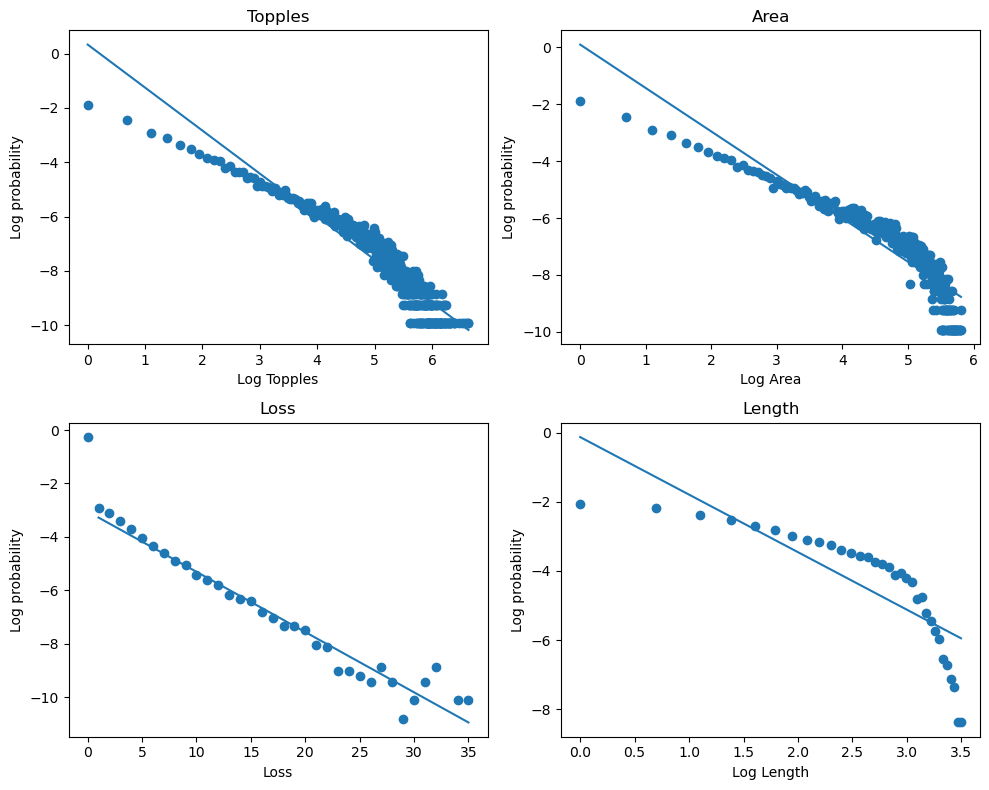

In [510]:
plot_properties(results_by_L[20][5000:])

In [521]:
def select_powerlaw_cutoff_length(
    data,
    r2_threshold=0.98,
    min_points=10
):
    data = data[data > 0]

    x, counts = np.unique(data, return_counts=True)
    prob = 1- (counts-counts.cumsum()) / counts.sum()

    results = []

    # Ensure that every fit contains at least min_points
    candidate_cutoffs = x[min_points - 1:]

    for cutoff in candidate_cutoffs:
        fit_mask = x <= cutoff

        log_x = np.log(x[fit_mask])
        log_prob = np.log(prob[fit_mask])

        alpha, logA = np.polyfit(log_x, log_prob, 1)

        log_prob_pred = alpha * log_x + logA
        r2 = r2_score(log_prob, log_prob_pred)

        results.append({
            "cutoff": cutoff,
            "alpha": alpha,
            "logA": logA,
            "r2": r2,
            "n_points": fit_mask.sum()
        })

    valid_results = [
        result for result in results
        if result["r2"] >= r2_threshold
    ]

    if len(valid_results) == 0:
        return None, results

    # Candidates are ordered, so the final valid one is the largest
    selected = valid_results[-1]

    return selected, results

#### Area

In [522]:
area_cutoffs = []
area_exponents = []

for L in L_values:
    area_data = results_by_L[L][5000:, 1]

    selected, _ = select_powerlaw_cutoff_length(
        area_data,
        r2_threshold=0.98,
        min_points=10
    )

    area_cutoffs.append(selected["cutoff"])
    area_exponents.append(-selected["alpha"])

    print(
        f"L={L}: "
        f"cutoff={selected['cutoff']}, "
        f"alpha={-selected['alpha']:.3f}, "
        f"R²={selected['r2']:.4f}"
    )

L=10: cutoff=30.0, alpha=-0.168, R²=0.9800
L=20: cutoff=169.0, alpha=-0.110, R²=0.9801
L=30: cutoff=302.0, alpha=-0.093, R²=0.9800
L=40: cutoff=593.0, alpha=-0.081, R²=0.9800
L=50: cutoff=984.0, alpha=-0.074, R²=0.9800


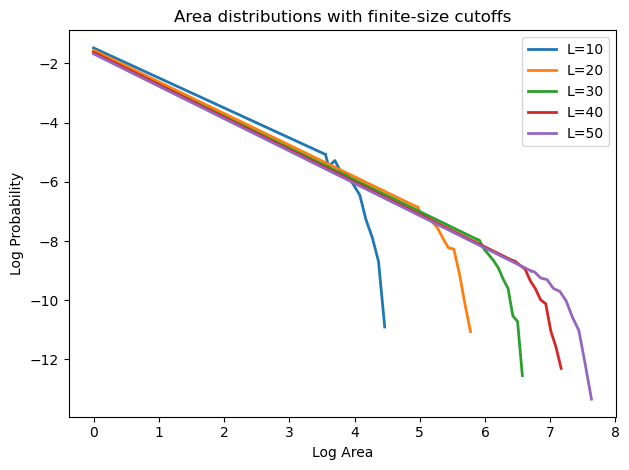

In [ ]:
L_values = [10, 20, 30, 40, 50]

cutoffs = {
    10: 30,
    20: 144,
    30: 357,
    40: 613,
    50: 820
}

#plt.figure(figsize=(9, 7))

for i, L in enumerate(L_values):
    area = results_by_L[L][5000:, 1]
    area = area[area > 0]

    x, counts = np.unique(area, return_counts=True)
    prob = counts / counts.sum()

    cutoff = cutoffs[L]
    colour = f"C{i}"

    # Fitted straight power-law region
    fit_mask = x <= cutoff

    log_x_fit = np.log(x[fit_mask])
    log_prob_fit = np.log(prob[fit_mask])

    alpha, logA = np.polyfit(
        log_x_fit,
        log_prob_fit,
        1
    )

    fitted_log_prob = alpha * log_x_fit + logA

    plt.plot(
        log_x_fit,
        fitted_log_prob,
        color=colour,
        linewidth=2,
        label=f"L={L}"
    )


    # Log-binned trend in the tail
    tail = area[area > cutoff]

    if len(tail) > 0:
        number_tail_bins = 10

        tail_edges = np.exp(
            np.linspace(
                np.log(cutoff),
                np.log(tail.max() + 1),
                number_tail_bins + 1
            )
        )

        tail_counts, tail_edges = np.histogram(
            tail,
            bins=tail_edges
        )

        tail_widths = np.diff(tail_edges)

        # Geometric centre 
        tail_centres = np.sqrt(
            tail_edges[:-1] * tail_edges[1:]
        )

        # Probability per unit area, comparable with the original PMF
        tail_prob = tail_counts / (
            len(area) * tail_widths
        )

        nonempty = tail_counts > 0

        tail_centres = tail_centres[nonempty]
        tail_prob = tail_prob[nonempty]

        # Begin the tail curve at the end of the fitted line
        tail_log_x = np.concatenate([
            [np.log(cutoff)],
            np.log(tail_centres)
        ])

        tail_log_prob = np.concatenate([
            [alpha * np.log(cutoff) + logA],
            np.log(tail_prob)
        ])

        plt.plot(
            tail_log_x,
            tail_log_prob,
            color=colour,
            linewidth=2
        )

plt.xlabel("Log Area")
plt.ylabel("Log Probability")
plt.title("Area distributions with finite-size cutoffs")
plt.legend()
plt.tight_layout()
plt.show()

In [534]:
def plot_raw_distribution(L_values, results, colname, adjustment=False):
    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }

    col = name_to_col[colname]

    # positive area/topples/length
    pos_by_L = {}

    for L in L_values:
        pos = results[L][5000:, col]
        pos_by_L[L] = pos[pos > 0]

    # bins
    maximum = max(pos.max() for pos in pos_by_L.values())
    number_bins = 30

    # log bin edges
    bin_edges = np.unique(np.floor(np.geomspace(1, maximum + 1, number_bins + 1)).astype(int))

    if bin_edges[-1] <= maximum_area:
        bin_edges = np.append(bin_edges, maximum_area + 1)

    #plt.figure(figsize=(9, 7))

    for i, L in enumerate(L_values):
        pos = pos_by_L[L]

        counts, edges = np.histogram(pos, bins=bin_edges)
        widths = np.diff(edges)

        # geometric centres
        centres = np.sqrt(edges[:-1] * edges[1:])

        # empirical probability per unit area
        probability_density = counts / (len(area) * widths)

        if adjustment:
            N = L**2
            probability_density = (np.log(N) * probability_density)

        nonempty = counts > 0

        plt.plot(
            centres[nonempty],
            probability_density[nonempty],
            color=f"C{i}",
            linewidth=2,
            label=f"L={L}"
        )

    plt.xscale("log")
    plt.yscale("log")

    plt.xlabel(colname)

    if adjustment:
        plt.ylabel(r"$\log(N)\,P(" + colname + r")$")
        plt.title(
            colname
            + r" distributions with $\log(N)$ scaling for different system sizes (L)")
    else:
        plt.ylabel(r"$P(" + colname + r")$")
        plt.title(colname + " distributions for different system sizes (L)")
    
    plt.legend()
    plt.tight_layout()
    plt.show()



In [556]:
def collapse_deviation(cutoffs, results, colname, adjusted=False):
    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }

    col = name_to_col[colname]
    
    data_by_L = {}
    all_log_x = []
    all_log_prob = []

    for L in L_values:
        pos = results[L][5000:, col]
        pos = pos[pos > 0]

        x, counts = np.unique(pos, return_counts=True)
        prob = counts / counts.sum()

        # Use the same scaling region in both comparisons
        fit_mask = x <= cutoffs[L]

        log_x = np.log(x[fit_mask])
        log_prob = np.log(prob[fit_mask])

        if adjusted:
            # Assuming N is the number of sites in an L × L grid
            N = L**2
            log_prob = log_prob + np.log(np.log(N))

        data_by_L[L] = (log_x, log_prob)

        all_log_x.append(log_x)
        all_log_prob.append(log_prob)

    all_log_x = np.concatenate(all_log_x)
    all_log_prob = np.concatenate(all_log_prob)

    slope, intercept = np.polyfit(all_log_x, all_log_prob, 1)

    maximum_deviation_by_L = {}
    rmse_by_L = {}
    all_residuals = []

    for L, (log_x, log_prob) in data_by_L.items():
        fitted = slope * log_x + intercept
        residuals = log_prob - fitted

        maximum_deviation_by_L[L] = np.max(np.abs(residuals))

        rmse_by_L[L] = np.sqrt(np.mean(residuals**2))
        all_residuals.append(residuals)

    overall_maximum = max(maximum_deviation_by_L.values())
    all_residuals = np.concatenate(all_residuals)
    overall_rmse = np.sqrt(np.mean(all_residuals**2))

    return {
        "slope": slope,
        "intercept": intercept,
        "maximum_by_L": maximum_deviation_by_L,
        "rmse_by_L": rmse_by_L,
        "overall_maximum": overall_maximum,
        "overall_rmse": overall_rmse
    }

In [557]:
L_values = [10, 20, 30, 40, 50]

cutoffs = {
    10: 30,
    20: 144,
    30: 357,
    40: 613,
    50: 820
}

before = collapse_deviation(cutoffs, results_by_L, "Area", adjusted=False)
after = collapse_deviation(cutoffs, results_by_L, "Area", adjusted=True)

print("Before adjustment")
print("Slope:", before["slope"])
print("Maximum deviations:", before["maximum_by_L"])
print("Overall maximum:", before["overall_maximum"])
print("Overall rmse:", before["overall_rmse"])

print("\nAfter adjustment")
print("Slope:", after["slope"])
print("Maximum deviations:", after["maximum_by_L"])
print("Overall maximum:", after["overall_maximum"])
print("Overall rmse:", after["overall_rmse"])

Before adjustment
Slope: -1.1372568430118213
Maximum deviations: {10: np.float64(0.3748475665645685), 20: np.float64(0.6299400309000642), 30: np.float64(1.9492178869510663), 40: np.float64(1.5990630475143295), 50: np.float64(1.6618043294943199)}
Overall maximum: 1.9492178869510663
Overall rmse: 0.3971382012142488

After adjustment
Slope: -1.0939611431897165
Maximum deviations: {10: np.float64(0.43282081093693336), 20: np.float64(0.4563182492803399), 30: np.float64(2.0402482838546447), 40: np.float64(1.6222751987533108), 50: np.float64(1.6243557308749779)}
Overall maximum: 2.0402482838546447
Overall rmse: 0.3919173218352313


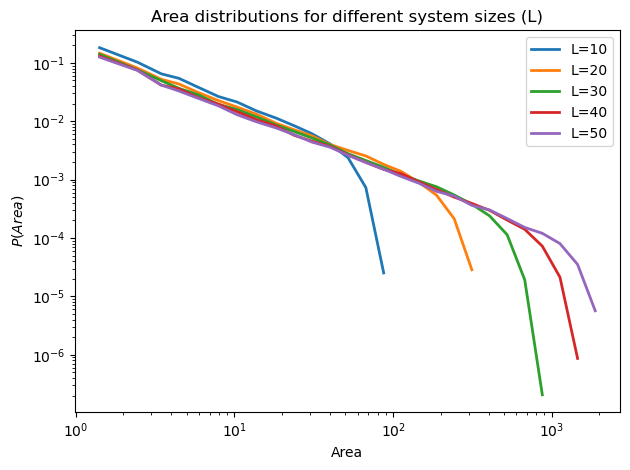

In [536]:
plot_raw_distribution(L_values, results_by_L, "Area")

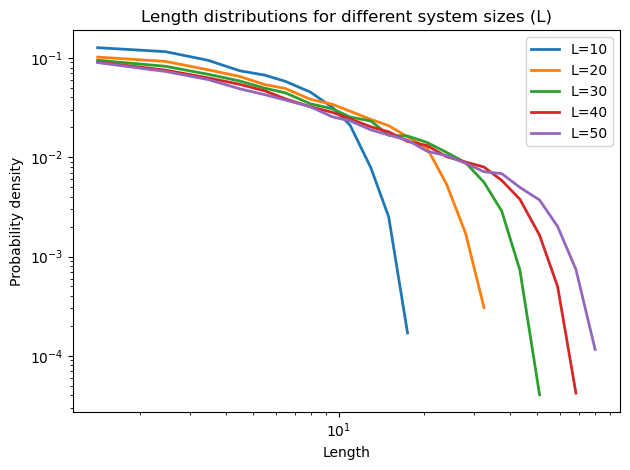

In [528]:
plot_raw_distribution(L_values, results_by_L, "Length")

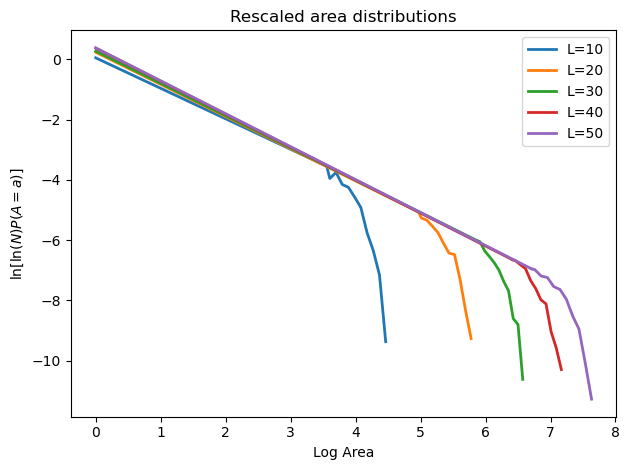

In [470]:
L_values = [10, 20, 30, 40, 50]

cutoffs = {
    10: 35,
    20: 144,
    30: 357,
    40: 613,
    50: 820
}

#plt.figure(figsize=(9, 7))

for i, L in enumerate(L_values):
    area = results_by_L[L][5000:, 1]
    area = area[area > 0]

    x, counts = np.unique(area, return_counts=True)
    prob = counts / counts.sum()

    cutoff = cutoffs[L]
    colour = f"C{i}"

    # Fitted straight power-law region
    fit_mask = x <= cutoff

    log_x_fit = np.log(x[fit_mask])
    log_prob_fit = np.log(prob[fit_mask])

    alpha, logA = np.polyfit(
        log_x_fit,
        log_prob_fit,
        1
    )

    fitted_log_prob = alpha * log_x_fit + logA
    N = L**2
    vertical_shift = np.log(np.log(N))

    plt.plot(
        log_x_fit,
        fitted_log_prob + vertical_shift,
        color=colour,
        linewidth=2,
        label=f"L={L}"
    )


    # Log-binned trend in the tail
    tail = area[area > cutoff]

    if len(tail) > 0:
        number_tail_bins = 10

        tail_edges = np.exp(
            np.linspace(
                np.log(cutoff),
                np.log(tail.max() + 1),
                number_tail_bins + 1
            )
        )

        tail_counts, tail_edges = np.histogram(
            tail,
            bins=tail_edges
        )

        tail_widths = np.diff(tail_edges)

        # Geometric centre is appropriate for logarithmic bins
        tail_centres = np.sqrt(
            tail_edges[:-1] * tail_edges[1:]
        )

        # Probability per unit area, comparable with the original PMF
        tail_prob = tail_counts / (
            len(area) * tail_widths
        )

        nonempty = tail_counts > 0

        tail_centres = tail_centres[nonempty]
        tail_prob = tail_prob[nonempty]

        # Begin the tail curve at the end of the fitted line
        tail_log_x = np.concatenate([
            [np.log(cutoff)],
            np.log(tail_centres)
        ])

        tail_log_prob = np.concatenate([
            [alpha * np.log(cutoff) + logA],
            np.log(tail_prob)
        ])

        tail_log_prob_scaled = tail_log_prob + vertical_shift


        plt.plot(
            tail_log_x,
            tail_log_prob_scaled,
            color=colour,
            linewidth=2
        )

plt.xlabel("Log Area")
plt.ylabel(r"$\ln[\ln(N)P(A=a)]$")
plt.title("Rescaled area distributions")
plt.legend()
plt.tight_layout()
plt.show()

In [472]:
L_values = np.array([10, 20, 30, 40, 50])
cutoff_values = np.array([35, 144, 357, 613, 820])

beta, intercept = np.polyfit(
    np.log(L_values),
    np.log(cutoff_values),
    1
)

predicted = (
    beta * np.log(L_values)
    + intercept
)

beta_r2 = r2_score(
    np.log(cutoff_values),
    predicted
)

print(f"beta = {beta:.3f}")
print(f"R² = {beta_r2:.3f}")

beta = 2.004
R² = 0.997


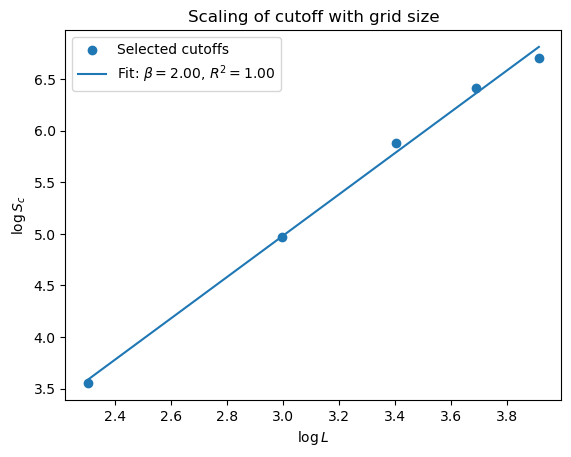

In [473]:
log_L = np.log(L_values)
log_cutoff = np.log(cutoff_values)

x_line = np.linspace(log_L.min(), log_L.max(), 100)
y_line = beta * x_line + intercept
plt.scatter(log_L, log_cutoff, label="Selected cutoffs")
plt.plot(x_line,y_line,label=fr"Fit: $\beta={beta:.2f}$, $R^2={beta_r2:.2f}$")

plt.xlabel(r"$\log L$")
plt.ylabel(r"$\log S_c$")
plt.title("Scaling of cutoff with grid size")
plt.legend()
plt.show()

#### Topples

In [558]:
topples_cutoffs = []
topples_exponents = []

for L in L_values:
    topples_data = results_by_L[L][5000:, 0]

    selected, _ = select_powerlaw_cutoff_length(
        topples_data,
        r2_threshold=0.98,
        min_points=10
    )

    topples_cutoffs.append(selected["cutoff"])
    topples_exponents.append(-selected["alpha"])

    print(
        f"L={L}: "
        f"cutoff={selected['cutoff']}, "
        f"alpha={-selected['alpha']:.3f}, "
        f"R²={selected['r2']:.4f}"
    )

L=10: cutoff=25.0, alpha=-0.172, R²=0.9801
L=20: cutoff=134.0, alpha=-0.112, R²=0.9800
L=30: cutoff=142.0, alpha=-0.101, R²=0.9800
L=40: cutoff=380.0, alpha=-0.084, R²=0.9800
L=50: cutoff=639.0, alpha=-0.076, R²=0.9800


In [559]:
L_values = [10, 20, 30, 40, 50]

cutoffs = {
    10: 25,
    20: 134,
    30: 142,
    40: 380,
    50: 639
}

before = collapse_deviation(cutoffs, results_by_L, "Area", adjusted=False)
after = collapse_deviation(cutoffs, results_by_L, "Area", adjusted=True)

print("Before adjustment")
print("Slope:", before["slope"])
print("Maximum deviations:", before["maximum_by_L"])
print("Overall maximum:", before["overall_maximum"])
print("Overall rmse:", before["overall_rmse"])

print("\nAfter adjustment")
print("Slope:", after["slope"])
print("Maximum deviations:", after["maximum_by_L"])
print("Overall maximum:", after["overall_maximum"])
print("Overall rmse:", after["overall_rmse"])

Before adjustment
Slope: -1.121865907211587
Maximum deviations: {10: np.float64(0.38038328056925064), 20: np.float64(0.628525763679697), 30: np.float64(0.4804222801905813), 40: np.float64(1.3609432409195765), 50: np.float64(1.6830530321592398)}
Overall maximum: 1.6830530321592398
Overall rmse: 0.33648060536860125

After adjustment
Slope: -1.0731107302607525
Maximum deviations: {10: np.float64(0.35128135426951007), 20: np.float64(0.4378634927512506), 30: np.float64(0.38403005742835017), 40: np.float64(1.3896529912308848), 50: np.float64(1.6696805994362105)}
Overall maximum: 1.6696805994362105
Overall rmse: 0.32633722532803594


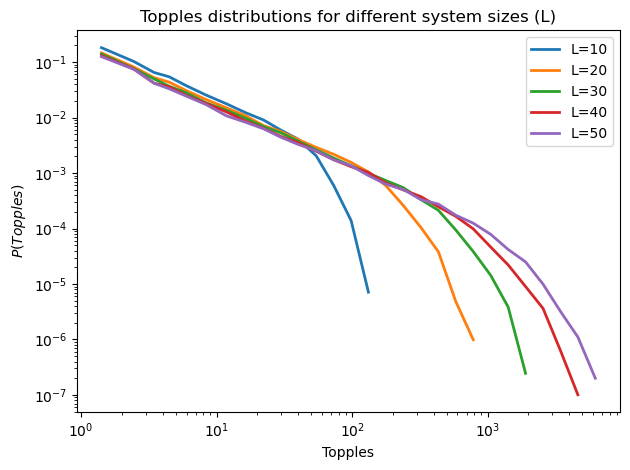

In [560]:
plot_raw_distribution(L_values, results_by_L, "Topples")

In [478]:
print("Mean: ", np.mean(topples_exponents))
print("sd: ", np.std(topples_exponents))

Mean:  -0.10979808745896438
sd:  0.031526998239972584


In [479]:

L_values = np.array([10, 20, 30, 40, 50])
cutoff_values = np.array([28, 112, 206, 199, 536])

beta, intercept = np.polyfit(
    np.log(L_values),
    np.log(cutoff_values),
    1
)

predicted = (
    beta * np.log(L_values)
    + intercept
)

beta_r2 = r2_score(
    np.log(cutoff_values),
    predicted
)

print(f"beta = {beta:.3f}")
print(f"R² = {beta_r2:.3f}")

beta = 1.659
R² = 0.946


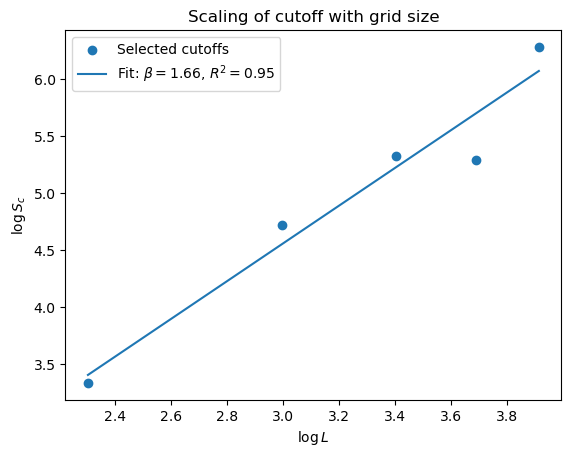

In [480]:
log_L = np.log(L_values)
log_cutoff = np.log(cutoff_values)

x_line = np.linspace(log_L.min(), log_L.max(), 100)
y_line = beta * x_line + intercept
plt.scatter(log_L, log_cutoff, label="Selected cutoffs")
plt.plot(x_line,y_line,label=fr"Fit: $\beta={beta:.2f}$, $R^2={beta_r2:.2f}$")

plt.xlabel(r"$\log L$")
plt.ylabel(r"$\log S_c$")
plt.title("Scaling of cutoff with grid size")
plt.legend()
plt.show()

#### Loss

In [348]:
def analyse_loss(data):
    x, counts = np.unique(data, return_counts=True)

    # Unconditional probability, including zero
    prob = counts / len(data)

    p_zero = np.mean(data == 0)

    # Fit positive losses only
    fit_mask = x > 0

    x_fit = x[fit_mask]
    log_prob_fit = np.log(prob[fit_mask])

    slope, logA = np.polyfit(
        x_fit,
        log_prob_fit,
        1
    )

    log_prob_pred = slope * x_fit + logA
    r2 = r2_score(log_prob_fit, log_prob_pred)

    decay_rate = -slope

    return {
        "x": x,
        "prob": prob,
        "x_fit": x_fit,
        "log_prob_pred": log_prob_pred,
        "p_zero": p_zero,
        "lambda": decay_rate,
        "logA": logA,
        "r2": r2
    }

In [481]:
loss_results = {}

for L in L_values:
    loss = results_by_L[L][5000:, 2]

    result = analyse_loss(loss)
    loss_results[L] = result

    print(
        f"L={L}: "
        f"P(loss=0)={result['p_zero']:.3f}, "
        f"lambda={result['lambda']:.3f}, "
        f"R²={result['r2']:.4f}"
    )

L=10: P(loss=0)=0.722, lambda=0.317, R²=0.9928
L=20: P(loss=0)=0.765, lambda=0.215, R²=0.9332
L=30: P(loss=0)=0.793, lambda=0.200, R²=0.9760
L=40: P(loss=0)=0.814, lambda=0.132, R²=0.8813
L=50: P(loss=0)=0.826, lambda=0.112, R²=0.8893


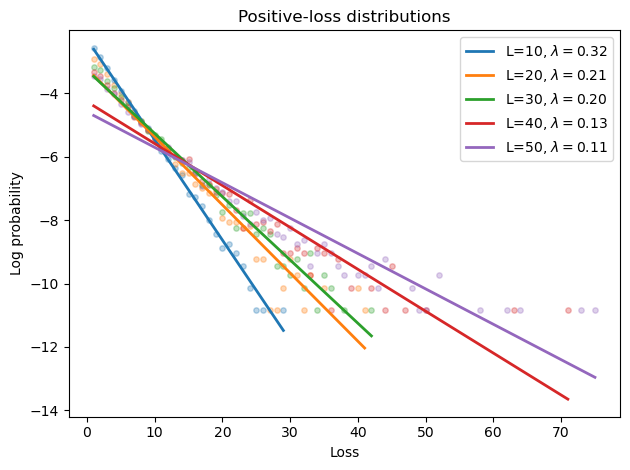

In [482]:
for i, L in enumerate(L_values):
    result = loss_results[L]
    colour = f"C{i}"

    positive_mask = result["x"] > 0

    plt.scatter(
        result["x"][positive_mask],
        np.log(result["prob"][positive_mask]),
        s=15,
        color=colour,
        alpha=0.3
    )

    plt.plot(
        result["x_fit"],
        result["log_prob_pred"],
        color=colour,
        linewidth=2,
        label=(
            f"L={L}, "
            fr"$\lambda={result['lambda']:.2f}$"
        )
    )

plt.xlabel("Loss")
plt.ylabel("Log probability")
plt.title("Positive-loss distributions")
plt.legend()
plt.tight_layout()
plt.show()

#### Length

In [517]:
def fit_powerlaw_length(data, x_max, L, title=None, plot=True):
    data = data[data > 0]

    x, counts = np.unique(data, return_counts=True)
    prob = 1 - (counts.cumsum()-counts) / counts.sum()

    fit_mask = x <= x_max

    log_x_fit = np.log(x[fit_mask])
    log_prob_fit = np.log(prob[fit_mask])
    log_prob_fit_1 = np.log(np.log(L**2)*prob[fit_mask])

    alpha, logA = np.polyfit(log_x_fit, log_prob_fit, 1)
    alpha_1, logA_1 = np.polyfit(log_x_fit, log_prob_fit, 1)

    log_prob_pred = alpha * log_x_fit + logA

    # R² on the same scale used for fitting
    r2 = r2_score(log_prob_fit, log_prob_pred)

    print(
        f"{title}: log prob = "
        f"{alpha:.2f} * log x + {logA:.2f}, "
        f"R² = {r2:.4f}"
    )

    if plot:
        # Show the complete empirical distribution
        plt.scatter(
            np.log(x),
            np.log(prob),
            label="Simulation"
        )

        # Show the fitted line only within the fitting range
        plt.plot(
            log_x_fit,
            log_prob_pred,
            color="red",
            label=f"Fit up to {x_max}"
        )

        plt.axvline(
            np.log(x_max),
            color="grey",
            linestyle=":",
            label="Cutoff"
        )

        plt.xlabel("Log " + (title or "x"))
        plt.ylabel("Log probability")
        plt.title(title)
        plt.legend()
        plt.show()

    return alpha, logA, r2


In [444]:
def select_powerlaw_cutoff_length(
    data,
    r2_threshold=0.98,
    min_points=10
):
    data = data[data > 0]

    x, counts = np.unique(data, return_counts=True)
    prob = 1- (counts-counts.cumsum()) / counts.sum()

    results = []

    # Ensure that every fit contains at least min_points
    candidate_cutoffs = x[min_points - 1:]

    for cutoff in candidate_cutoffs:
        fit_mask = x <= cutoff

        log_x = np.log(x[fit_mask])
        log_prob = np.log(prob[fit_mask])

        alpha, logA = np.polyfit(
            log_x,
            log_prob,
            1
        )

        log_prob_pred = alpha * log_x + logA
        r2 = r2_score(log_prob, log_prob_pred)

        results.append({
            "cutoff": cutoff,
            "alpha": alpha,
            "logA": logA,
            "r2": r2,
            "n_points": fit_mask.sum()
        })

    valid_results = [
        result for result in results
        if result["r2"] >= r2_threshold
    ]

    if len(valid_results) == 0:
        return None, results

    # Candidates are ordered, so the final valid one is the largest
    selected = valid_results[-1]

    return selected, results

In [455]:
length_cutoffs = []
length_exponents = []

for L in L_values:
    length_data = results_by_L[L][5000:, 3]

    selected, _ = select_powerlaw_cutoff_length(
        length_data,
        r2_threshold=0.90,
        min_points=5
    )

    length_cutoffs.append(selected["cutoff"])
    length_exponents.append(-selected["alpha"])

    print(
        f"L={L}: "
        f"cutoff={selected['cutoff']}, "
        f"alpha={-selected['alpha']:.3f}, "
        f"R²={selected['r2']:.4f}"
    )

L=10: cutoff=17.0, alpha=-0.260, R²=0.9782
L=20: cutoff=35.0, alpha=-0.205, R²=0.9760
L=30: cutoff=51.0, alpha=-0.183, R²=0.9777
L=40: cutoff=71.0, alpha=-0.169, R²=0.9789


Length: log prob = -0.50 * log x + 0.29, R² = 0.9189


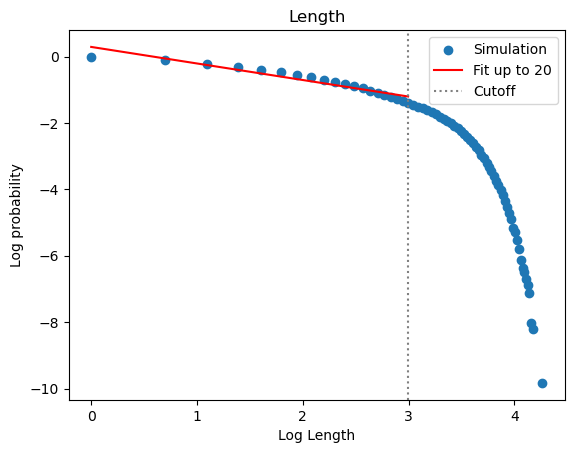

(np.float64(-0.49825933551777685),
 np.float64(0.28868583784015034),
 0.9188915841080889)

In [454]:
fit_powerlaw_length(results_by_L[40][5000:, 3], 20, "Length", True)

### Extension

In [494]:
np.random.seed(12345)

L_values = [10, 20, 30, 40, 50]
results_by_L_ext = {}

for L in L_values:
    results_by_L_ext[L] = simulate_avalanche(T=55000, width=L, height=L, manna=True)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

Topples: log prob = -1.40 * log x + -0.65
Area: log prob = -1.59 * log x + 0.10
Loss: log prob = -0.14 * x + -3.94
Length: log prob = -2.17 * log x + 0.73


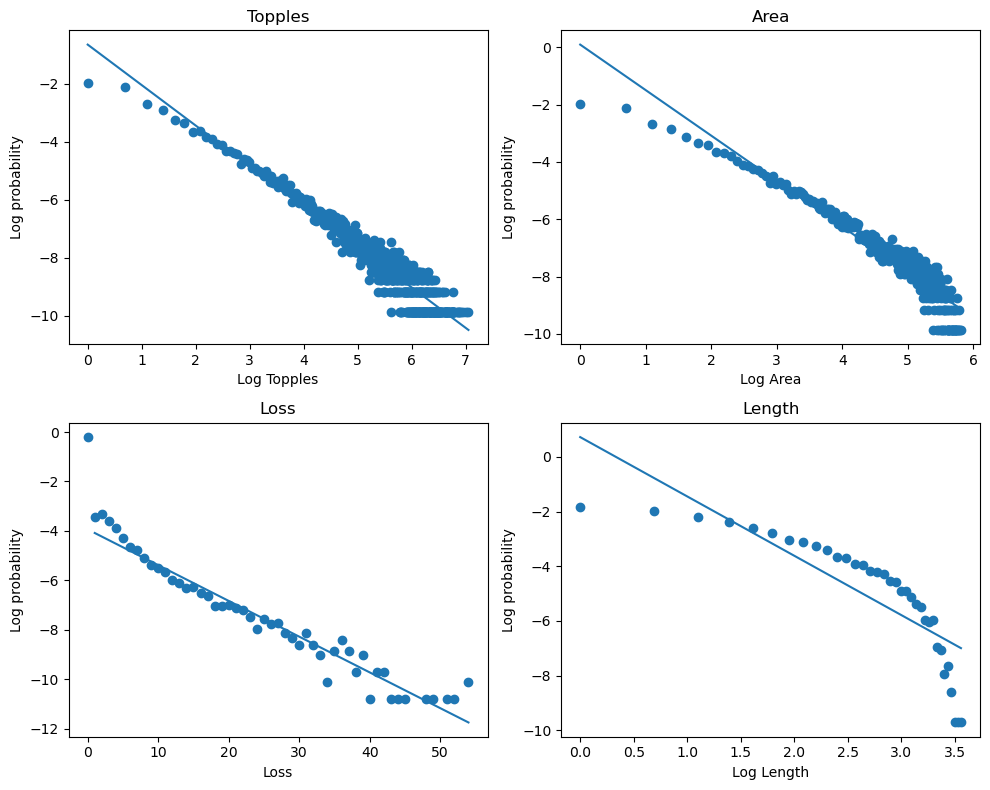

In [484]:
plot_properties(results_by_L_ext[20][5000:])

#### Area

In [485]:
L_values = [10,20,30,40,50]
area_cutoffs = []
area_exponents = []

for L in L_values:
    area_data = results_by_L_ext[L][5000:, 1]

    selected, _ = select_powerlaw_cutoff_length(
        area_data,
        r2_threshold=0.98,
        min_points=10
    )

    area_cutoffs.append(selected["cutoff"])
    area_exponents.append(-selected["alpha"])

    print(
        f"L={L}: "
        f"cutoff={selected['cutoff']}, "
        f"alpha={-selected['alpha']:.3f}, "
        f"R²={selected['r2']:.4f}"
    )

L=10: cutoff=19.0, alpha=-0.198, R²=0.9810
L=20: cutoff=33.0, alpha=-0.157, R²=0.9802
L=30: cutoff=36.0, alpha=-0.146, R²=0.9803
L=40: cutoff=37.0, alpha=-0.141, R²=0.9801
L=50: cutoff=43.0, alpha=-0.134, R²=0.9802


In [428]:
def plot_finite_size_cutoffs(L_vals, cutoffs, results, colname, rescale = False):
    
    cols = {"Topples": 0,
            "Area": 1,
            "Length": 3}
    col = cols[colname]

    
    for i, L in enumerate(L_vals):
        area = results[L][5000:, col]
        area = area[area > 0]

        x, counts = np.unique(area, return_counts=True)
        prob = counts / counts.sum()

        cutoff = cutoffs[L]
        colour = f"C{i}"

        vertical_shift = 0
        if rescale:
            N = L**2
            vertical_shift = np.log(np.log(N))

        # Fitted straight power-law region
        fit_mask = x <= cutoff

        log_x_fit = np.log(x[fit_mask])
        log_prob_fit = np.log(prob[fit_mask])

        alpha, logA = np.polyfit(
            log_x_fit,
            log_prob_fit,
            1
        )

        fitted_log_prob = alpha * log_x_fit + logA

        plt.plot(
            log_x_fit,
            fitted_log_prob+vertical_shift,
            color=colour,
            linewidth=2,
            label=f"L={L}"
        )


        # Log-binned trend in the tail
        tail = area[area > cutoff]

        if len(tail) > 0:
            number_tail_bins = 10

            tail_edges = np.exp(
                np.linspace(
                    np.log(cutoff),
                    np.log(tail.max() + 1),
                    number_tail_bins + 1
                )
            )

            tail_counts, tail_edges = np.histogram(
                tail,
                bins=tail_edges
            )

            tail_widths = np.diff(tail_edges)

            # Geometric centre is appropriate for logarithmic bins
            tail_centres = np.sqrt(
                tail_edges[:-1] * tail_edges[1:]
            )

            # Probability per unit area, comparable with the original PMF
            tail_prob = tail_counts / (
                len(area) * tail_widths
            )

            nonempty = tail_counts > 0

            tail_centres = tail_centres[nonempty]
            tail_prob = tail_prob[nonempty]

            # Begin the tail curve at the end of the fitted line
            tail_log_x = np.concatenate([
                [np.log(cutoff)],
                np.log(tail_centres)
            ])

            tail_log_prob = np.concatenate([
                [alpha * np.log(cutoff) + logA],
                np.log(tail_prob)
            ])

            plt.plot(
                tail_log_x,
                tail_log_prob+vertical_shift,
                color=colour,
                linewidth=2
            )

    plt.xlabel("Log Area")
    plt.ylabel("Log Probability")
    plt.title("Area distributions with finite-size cutoffs")
    plt.legend()
    plt.tight_layout()
    plt.show()


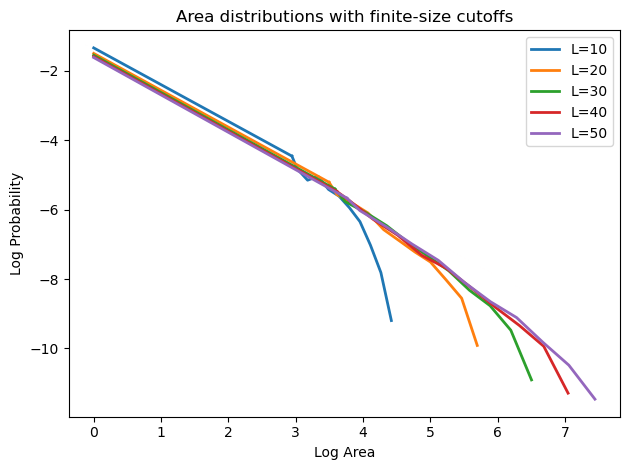

In [486]:
L_values = [10, 20, 30, 40, 50]

cutoffs = {
    10: 19,
    20: 33,
    30: 36,
    40: 37,
    50: 43
}

plot_finite_size_cutoffs(L_values, cutoffs, results_by_L_ext, "Area")

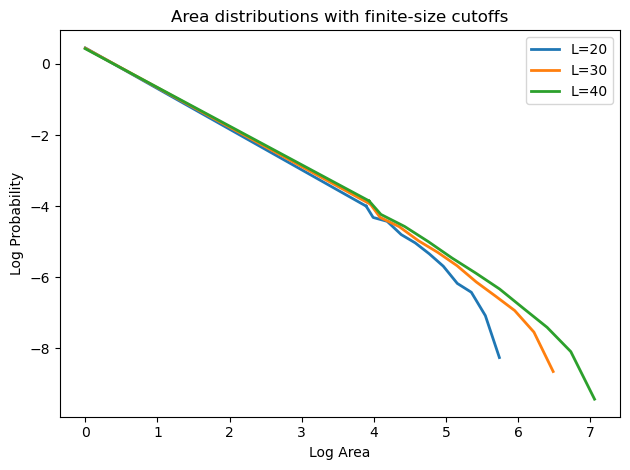

In [430]:
L_values = [20, 30, 40]

cutoffs = {
    20: 49,
    30: 52,
    40: 51
}

plot_finite_size_cutoffs(L_values, cutoffs, results_by_L_ext, "Area", True)

In [431]:
print("Mean: ", np.mean(area_exponents))
print("sd: ", np.std(area_exponents))

Mean:  1.1154225150286081
sd:  0.022542477200821698


#### Topples

In [432]:
L_values = [10,20,30,40]
topples_cutoffs = []
topples_exponents = []

for L in L_values:
    topples_data = results_by_L_ext[L][5000:, 0]

    selected, _ = select_powerlaw_cutoff(
        topples_data,
        r2_threshold=0.98,
        min_points=10
    )

    topples_cutoffs.append(selected["cutoff"])
    topples_exponents.append(-selected["alpha"])

    print(
        f"L={L}: "
        f"cutoff={selected['cutoff']}, "
        f"alpha={-selected['alpha']:.3f}, "
        f"R²={selected['r2']:.4f}"
    )

L=10: cutoff=51.0, alpha=1.250, R²=0.9814
L=20: cutoff=40.0, alpha=1.102, R²=0.9820
L=30: cutoff=78.0, alpha=1.149, R²=0.9852
L=40: cutoff=77.0, alpha=1.145, R²=0.9808


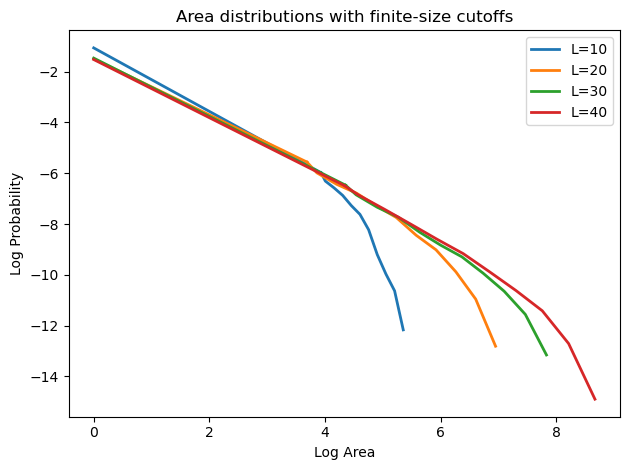

In [433]:
L_values = [10, 20, 30, 40]

cutoffs = {
    10: 51,
    20: 40,
    30: 78,
    40: 77
}

plot_finite_size_cutoffs(L_values, cutoffs, results_by_L_ext, "Topples")

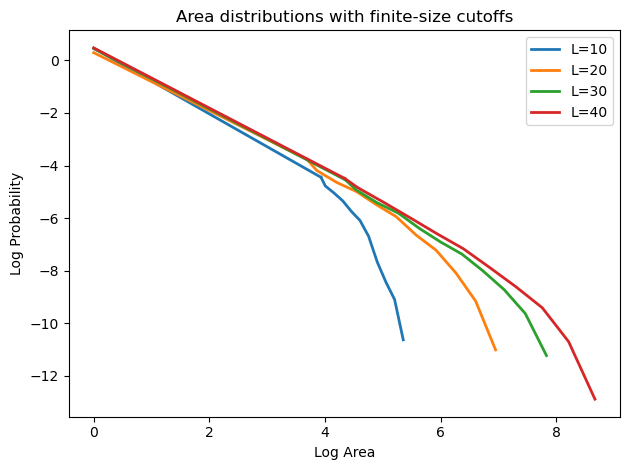

In [434]:
L_values = [10, 20, 30, 40]

cutoffs = {
    10: 51,
    20: 40,
    30: 78,
    40: 77
}

plot_finite_size_cutoffs(L_values, cutoffs, results_by_L_ext, "Topples", True)

In [435]:
print("Mean: ", np.mean(topples_exponents))
print("sd: ", np.std(topples_exponents))

Mean:  1.1613317698088068
sd:  0.05439115349249423


#### Loss

In [436]:
loss_results = {}

for L in L_values:
    loss = results_by_L_ext[L][5000:, 2]

    result = analyse_loss(loss)
    loss_results[L] = result

    print(
        f"L={L}: "
        f"P(loss=0)={result['p_zero']:.3f}, "
        f"lambda={result['lambda']:.3f}, "
        f"R²={result['r2']:.4f}"
    )

L=10: P(loss=0)=0.765, lambda=0.218, R²=0.9643
L=20: P(loss=0)=0.816, lambda=0.123, R²=0.9305
L=30: P(loss=0)=0.845, lambda=0.102, R²=0.9119
L=40: P(loss=0)=0.863, lambda=0.082, R²=0.8772


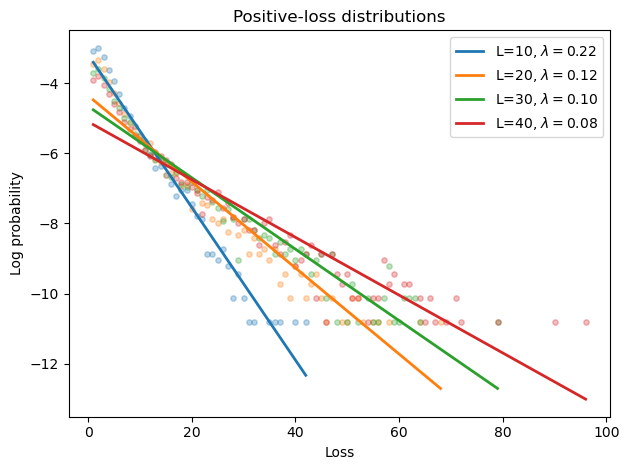

In [437]:
for i, L in enumerate(L_values):
    result = loss_results[L]
    colour = f"C{i}"

    positive_mask = result["x"] > 0

    plt.scatter(
        result["x"][positive_mask],
        np.log(result["prob"][positive_mask]),
        s=15,
        color=colour,
        alpha=0.3
    )

    plt.plot(
        result["x_fit"],
        result["log_prob_pred"],
        color=colour,
        linewidth=2,
        label=(
            f"L={L}, "
            fr"$\lambda={result['lambda']:.2f}$"
        )
    )

plt.xlabel("Loss")
plt.ylabel("Log probability")
plt.title("Positive-loss distributions")
plt.legend()
plt.tight_layout()
plt.show()

#### Length

In [438]:
length_cutoffs = []
length_exponents = []

for L in L_values:
    length_data = results_by_L[L][5000:, 3]

    selected, _ = select_powerlaw_cutoff(
        length_data,
        r2_threshold=0.90,
        min_points=5
    )

    length_cutoffs.append(selected["cutoff"])
    length_exponents.append(-selected["alpha"])

    print(
        f"L={L}: "
        f"cutoff={selected['cutoff']}, "
        f"alpha={-selected['alpha']:.3f}, "
        f"R²={selected['r2']:.4f}"
    )

L=10: cutoff=9.0, alpha=0.609, R²=0.9029
L=20: cutoff=21.0, alpha=0.811, R²=0.9081
L=30: cutoff=35.0, alpha=0.937, R²=0.9077
L=40: cutoff=50.0, alpha=1.024, R²=0.9019


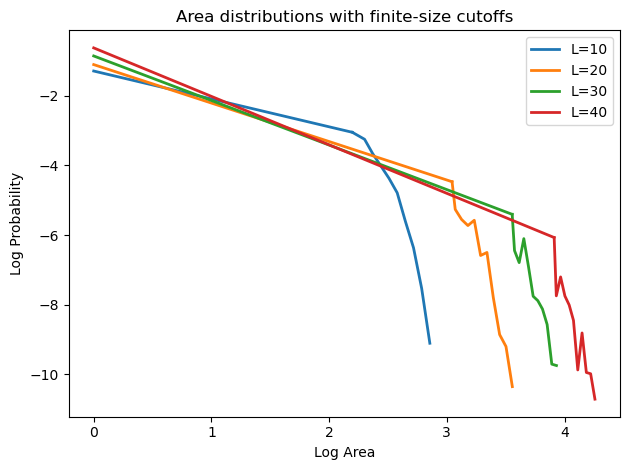

In [441]:
L_values = [10, 20, 30, 40]

cutoffs = {
    10: 9,
    20: 21,
    30: 35,
    40: 50
}

plot_finite_size_cutoffs(L_values, cutoffs, results_by_L_ext, "Length")

In [327]:
def compare_length_models(data, x_max):
    positive = data[data > 0]

    x, counts = np.unique(positive, return_counts=True)
    prob = counts / counts.sum()

    fit_mask = x <= x_max

    x_fit = x[fit_mask]
    log_prob = np.log(prob[fit_mask])

    # Power-law fit
    power_slope, power_intercept = np.polyfit(
        np.log(x_fit),
        log_prob,
        1
    )

    power_prediction = (
        power_slope * np.log(x_fit)
        + power_intercept
    )

    power_r2 = r2_score(
        log_prob,
        power_prediction
    )

    # Exponential fit
    exp_slope, exp_intercept = np.polyfit(
        x_fit,
        log_prob,
        1
    )

    exp_prediction = (
        exp_slope * x_fit
        + exp_intercept
    )

    exp_r2 = r2_score(
        log_prob,
        exp_prediction
    )

    print(
        f"Power law: alpha={-power_slope:.3f}, "
        f"R²={power_r2:.4f}"
    )

    print(
        f"Exponential: lambda={-exp_slope:.3f}, "
        f"R²={exp_r2:.4f}"
    )

    return {
        "power_alpha": -power_slope,
        "power_r2": power_r2,
        "exp_lambda": -exp_slope,
        "exp_r2": exp_r2
    }

In [329]:
compare_length_models(results_by_L[20][5000:, 3], 20)

Power law: alpha=0.767, R²=0.9135
Exponential: lambda=0.109, R²=0.9779


{'power_alpha': np.float64(0.7666341973093057),
 'power_r2': 0.9135474319694123,
 'exp_lambda': np.float64(0.10896368942909866),
 'exp_r2': 0.9779400517090454}

In [281]:
np.power(np.e, 5)

np.float64(148.41315910257657)

In [282]:
candidate_cutoff = [100, 150, 200, 250, 300, 350, 400]

for cand in candidate_cutoff:
    _, _, r2 = fit_powerlaw(results_1[5000:, 0], cand, "Topple", False)
    print(r2)

Topple: log prob = -1.03 * log x + -1.70, R² = 0.9906
0.9906123070426566
Topple: log prob = -1.07 * log x + -1.58, R² = 0.9843
0.984251074770021
Topple: log prob = -1.12 * log x + -1.41, R² = 0.9736
0.9735933821469394
Topple: log prob = -1.23 * log x + -1.03, R² = 0.9398
0.9398040604835092
Topple: log prob = -1.35 * log x + -0.58, R² = 0.9086
0.9085818420014586
Topple: log prob = -1.47 * log x + -0.14, R² = 0.8871
0.8871143738172927
Topple: log prob = -1.57 * log x + 0.26, R² = 0.8732
0.8732377942180107


Topple: log prob = -1.09 * log x + -1.52, R² = 0.9802


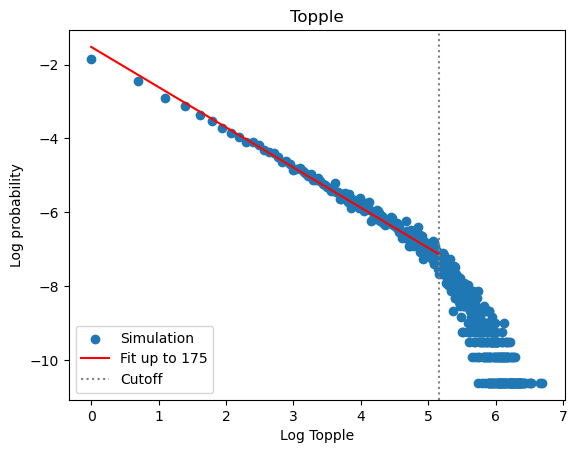

(np.float64(-1.0880243474474363),
 np.float64(-1.5209012892767313),
 0.9801661149708248)

In [283]:
fit_powerlaw(results_1[:, 0], 175, "Topple", True)

In [284]:
candidate_cutoff = [25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300]

for cand in candidate_cutoff:
    _, _, r2 = fit_powerlaw(results_1[:, 1], cand, "Area", False)
    print(r2)


Area: log prob = -0.98 * log x + -1.80, R² = 0.9977
0.9976520307154377
Area: log prob = -1.00 * log x + -1.75, R² = 0.9958
0.995770839800682
Area: log prob = -1.01 * log x + -1.73, R² = 0.9932
0.9931940346812003
Area: log prob = -1.03 * log x + -1.68, R² = 0.9898
0.9897572859084504
Area: log prob = -1.04 * log x + -1.64, R² = 0.9880
0.988009143912878
Area: log prob = -1.05 * log x + -1.63, R² = 0.9871
0.9870560241802744
Area: log prob = -1.08 * log x + -1.53, R² = 0.9809
0.9808734835631111
Area: log prob = -1.12 * log x + -1.38, R² = 0.9697
0.9697261059065211
Area: log prob = -1.17 * log x + -1.21, R² = 0.9594
0.9593920548682292
Area: log prob = -1.25 * log x + -0.93, R² = 0.9287
0.9286905602502163
Area: log prob = -1.33 * log x + -0.62, R² = 0.8995
0.899500285084528
Area: log prob = -1.45 * log x + -0.20, R² = 0.8567
0.8566895907265428


Area: log prob = -1.03 * log x + -1.68, R² = 0.9898


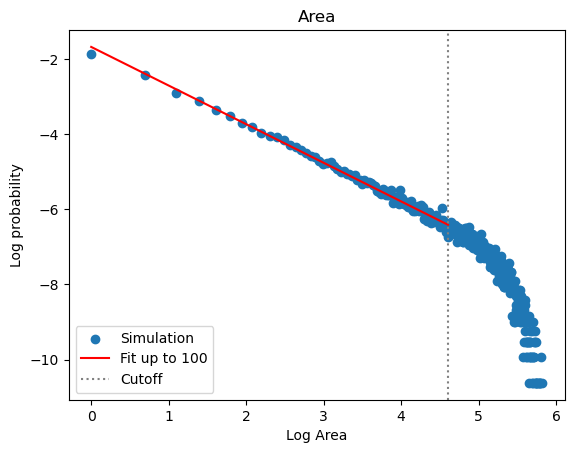

(np.float64(-1.0276006332976286),
 np.float64(-1.6801174671365842),
 0.9897572859084504)

In [285]:
fit_powerlaw(results_1[:, 1], 100, "Area", True)

In [286]:
candidate_cutoff = [10,12,14,16,18,20,22,24,26]

for cand in candidate_cutoff:
    fit_powerlaw(results_1[:, 3], cand, "Length", False)


Length: log prob = -0.57 * log x + -1.86, R² = 0.9348
Length: log prob = -0.62 * log x + -1.82, R² = 0.9385
Length: log prob = -0.64 * log x + -1.79, R² = 0.9473
Length: log prob = -0.68 * log x + -1.75, R² = 0.9473
Length: log prob = -0.72 * log x + -1.70, R² = 0.9448
Length: log prob = -0.76 * log x + -1.63, R² = 0.9344
Length: log prob = -0.84 * log x + -1.52, R² = 0.8951
Length: log prob = -0.93 * log x + -1.39, R² = 0.8614
Length: log prob = -1.05 * log x + -1.20, R² = 0.8089


Length: log prob = -0.76 * log x + -1.63, R² = 0.9344


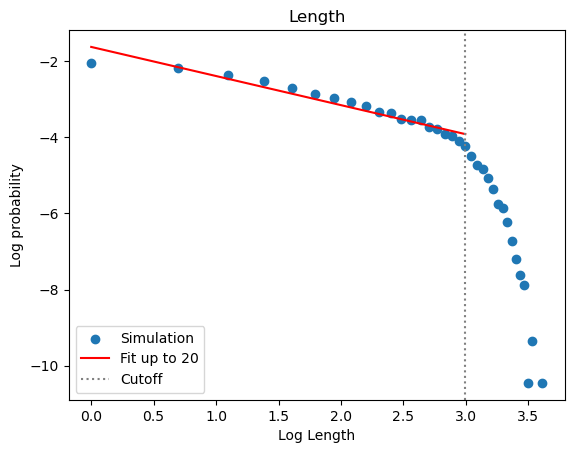

(np.float64(-0.763783437398213),
 np.float64(-1.6327788492408757),
 0.9344277423443125)

In [287]:
fit_powerlaw(results_1[:, 3], 20, "Length", True)

In [288]:
def fit_exp(data, x_max, title = None, plot = True):

    data = data[data>0]

    x, counts = np.unique(data, return_counts = True)
    prob = counts / counts.sum()

    if x_max is None:
        x_max = max(data)

    alpha, logA = np.polyfit((x[x<=x_max]), np.log(prob[x<=x_max]), 1)
    print(f"log prob = {alpha:.2f}* x + {logA:.2f}")

    if plot:
        plt.plot(x, alpha*x+logA)
        plt.scatter(x, np.log(prob))

        plt.xlabel(title)
        plt.ylabel("Log prob")
        plt.title(title)

        plt.show()

    return alpha, logA


In [289]:
from sklearn.metrics import r2_score

In [290]:
candidate_cutoff = [20,24,28,32,36,40]

for cand in candidate_cutoff:
    fit_exp(results_1[:, 2], cand, "Loss", False)    


log prob = -0.26* x + -1.28
log prob = -0.24* x + -1.38
log prob = -0.25* x + -1.36
log prob = -0.24* x + -1.42
log prob = -0.24* x + -1.42
log prob = -0.24* x + -1.42


log prob = -0.23* x + -1.61


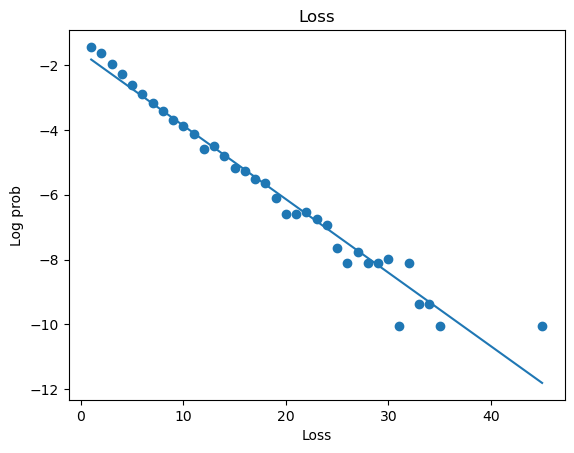

(np.float64(-0.22663149282599618), np.float64(-1.6054968854404443))

In [291]:
fit_exp(results_1[:, 2], None, "Loss", True)

In [292]:
def fit_powerlaw_sub(data, x_max, title = None, ax = True):

    data = data[data>0]

    x, counts = np.unique(data, return_counts = True)
    prob = counts / counts.sum()

    alpha, logA = np.polyfit(np.log(x[x<=x_max]), np.log(prob[x<=x_max]), 1)
    print(f"log prob = {alpha:.2f}*log x + {logA:.2f}")

    if ax is not None:
        ax.plot(np.log(x), alpha*np.log(x)+logA)
        ax.scatter(np.log(x), np.log(prob))

        ax.set_xlabel("Log "+title)
        ax.set_ylabel("Log prob")
        ax.set_title(title)

    return alpha, logA


In [293]:
def fit_exp_sub(data, x_max, title = None, ax = True):

    #data = data[data>0]

    x, counts = np.unique(data, return_counts = True)
    prob = counts / counts.sum()

    if x_max is None:
        x_max = max(data)

    alpha, logA = np.polyfit((x[(x>0) & (x<=x_max)]), np.log(prob[(x>0) & (x<=x_max)]), 1)
    print(f"log prob = {alpha:.2f}* x + {logA:.2f}")

    if ax is not None:
        ax.plot(x, alpha*x+logA)
        ax.scatter(x, np.log(prob))

        ax.set_xlabel(title)
        ax.set_ylabel("Log prob")
        ax.set_title(title)

    return alpha, logA


log prob = -1.07*log x + -1.58
log prob = -1.05*log x + -1.63
log prob = -0.23* x + -3.06
log prob = -0.76*log x + -1.63


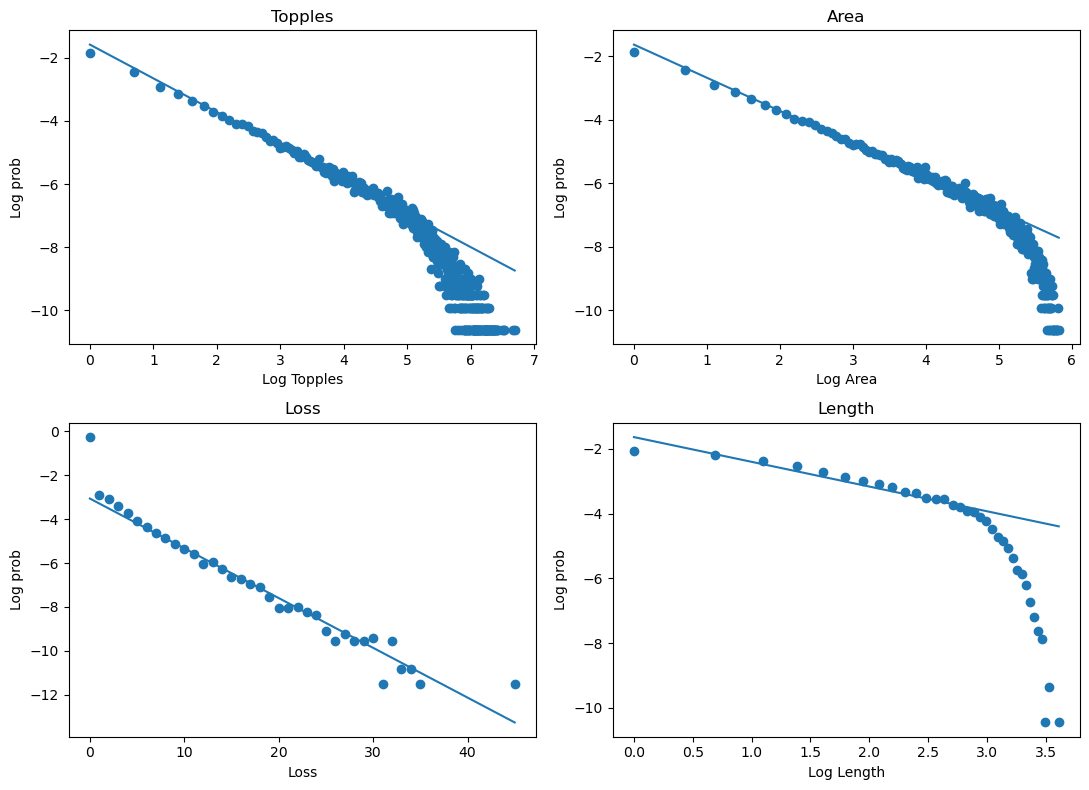

In [294]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

fit_powerlaw_sub(
    results_1[:, 0],
    x_max=150,
    title="Topples",
    ax=axes[0, 0]
)

fit_powerlaw_sub(
    results_1[:, 1],
    x_max=150,
    title="Area",
    ax=axes[0, 1]
)

fit_exp_sub(
    results_1[:, 2],
    x_max=None,
    title="Loss",
    ax=axes[1, 0]
)

fit_powerlaw_sub(
    results_1[:, 3],
    x_max=20,
    title="Length",
    ax=axes[1, 1]
)

fig.tight_layout()
plt.show()